# 07 — How the optimum moves with idle-noise strength, and why

Across idle strengths, with gates held fixed: does Δt* follow the
scaling the paper's ansatz implies, and where does waiting stop paying?

**Source:** `python -m qec_timing.studies.idle_scaling --placement uniform` →
`results/idle_scaling/idle_scaling_uniform.json`. Textbook gates, idle noise on every qubit
during each layer and the wait (as in notebook 04), X basis, H2 ratios scaled to
p2 = 5×10⁻³, T = 192, 2 × 100k shots per point. Linear γ/p2 ∈ {0.15, 0.3, 0.6},
quadratic c/p2 ∈ {0.0025, 0.01, 0.04}. The ansatz R = (A/Δt)(1 + q(Δt)/p_e)^α is fitted per
distance to all six curves and then predicts Δt* for any idle error per round.

q(Δt) is the idle Z error on a data qubit over one period, composed exactly as the circuit
applies it: 7 separately twirled chunks of t_R/7 inside the round and one of (Δt − 1)·t_R for
the wait. The quadratic term restarts in every chunk, so inside the round it contributes
about c/7, not c. Idle on the ancillas (which acts like readout error) is not in the ansatz.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
isc = json.loads((R / "idle_scaling" / "idle_scaling_uniform.json").read_text())
ref = json.loads((R / "idle_scaling" / "idle_scaling.json").read_text())   # data-only idle
for r in isc["rows"]:
    s, f = r["slopes"], r["ansatz"]
    print(f"d={r['d']}: slope linear {s['lin']['slope']:.3f} ± {s['lin']['se']:.3f} (predicted -1), "
          f"quadratic {s['quad']['slope']:.3f} ± {s['quad']['se']:.3f} (predicted -0.5);  "
          f"alpha {f['alpha']:.2f} ± {f['alpha_se']:.2f} -> g = {f['implied_g']:.2f} (paper 0.8)")

d=3: slope linear -0.997 ± 0.020 (predicted -1), quadratic -0.495 ± 0.010 (predicted -0.5);  alpha 1.45 ± 0.02 -> g = 0.73 (paper 0.8)
d=5: slope linear -1.040 ± 0.020 (predicted -1), quadratic -0.493 ± 0.010 (predicted -0.5);  alpha 1.75 ± 0.03 -> g = 0.58 (paper 0.8)
d=7: slope linear -1.052 ± 0.020 (predicted -1), quadratic -0.476 ± 0.010 (predicted -0.5);  alpha 1.95 ± 0.05 -> g = 0.49 (paper 0.8)


In [3]:
# Idle on every qubit against idle on the data only (the original repo's setup), same seeds.
print(f"{'d':>2} {'idle':<12}{'data only':>10}{'every qubit':>13}{'change':>8}")
for r, r0 in zip(isc["rows"], ref["rows"]):
    pairs = [(f"{c['family']} {c['value']:g}", c0["optimum"]["dt_star"], c["optimum"]["dt_star"])
             for c, c0 in zip(r["curves"], r0["curves"])]
    pairs.append(("mixed (held)", r0["held_out"]["optimum"]["dt_star"], r["held_out"]["optimum"]["dt_star"]))
    for lab, a, b in pairs:
        print(f"{r['d']:>2} {lab:<12}{a:>10.2f}{b:>13.2f}{b / a - 1:>+8.0%}")

 d idle         data only  every qubit  change
 3 lin 0.15         19.70        20.47     +4%
 3 lin 0.3           9.64        10.12     +5%
 3 lin 0.6           4.54         5.14    +13%
 3 quad 0.0025      16.65        17.05     +2%
 3 quad 0.01         8.05         8.25     +2%
 3 quad 0.04         4.05         4.32     +7%
 3 mixed (held)      5.10         5.50     +8%
 5 lin 0.15         10.89        11.25     +3%
 5 lin 0.3           5.12         5.35     +5%
 5 lin 0.6           2.49         2.66     +7%
 5 quad 0.0025      14.27        14.48     +1%
 5 quad 0.01         6.77         7.19     +6%
 5 quad 0.04         3.37         3.69     +9%
 5 mixed (held)      3.55         3.80     +7%
 7 lin 0.15          7.13         7.32     +3%
 7 lin 0.3           3.38         3.49     +3%
 7 lin 0.6           1.64         1.70     +4%
 7 quad 0.0025      12.25        12.47     +2%
 7 quad 0.01         6.01         6.59    +10%
 7 quad 0.04         2.88         3.34    +16%
 7 mixed (hel

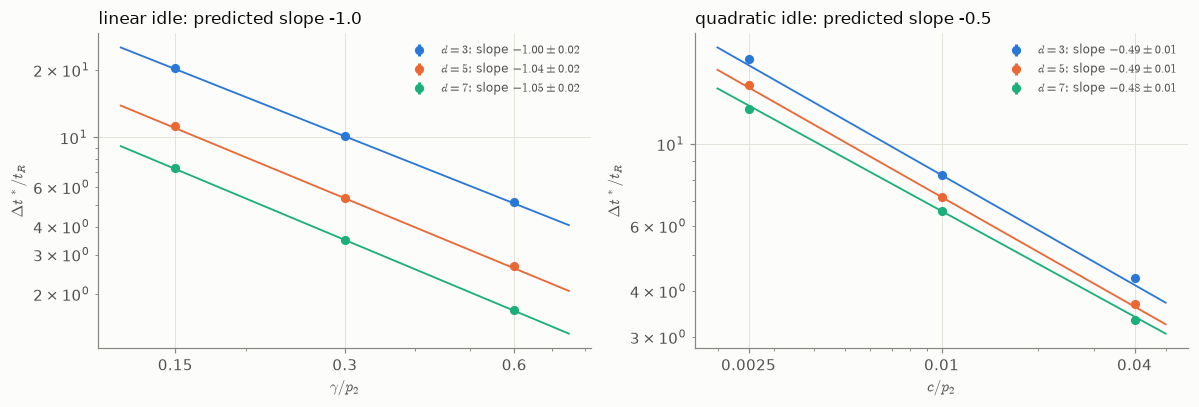

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, fam, xlab, pred in ((axes[0], "lin", r"$\gamma / p_2$", -1.0), (axes[1], "quad", r"$c / p_2$", -0.5)):
    for r in isc["rows"]:
        cs = [c for c in r["curves"] if c["family"] == fam]
        x = np.array([c["value"] for c in cs]); y = np.array([c["optimum"]["dt_star"] for c in cs])
        lo = y - np.array([c["optimum"]["lo"] for c in cs]); hi = np.array([c["optimum"]["hi"] for c in cs]) - y
        ax.errorbar(x, y, yerr=[lo, hi], fmt="o", color=P.D_COLOR[r["d"]], ms=5,
                    label=rf"$d = {r['d']}$: slope ${r['slopes'][fam]['slope']:.2f} \pm {r['slopes'][fam]['se']:.2f}$")
        m = r["slopes"][fam]["slope"]; xs = np.geomspace(x.min() * 0.8, x.max() * 1.25, 20)
        ax.plot(xs, y[1] * (xs / x[1]) ** m, "-", color=P.D_COLOR[r["d"]], lw=1.2)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.legend(fontsize=8)
    ax.set_xticks(x, [f"{v:g}" for v in x]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel(xlab); ax.set_ylabel(r"$\Delta t^* / t_R$")
    ax.set_title(f"{'linear' if fam == 'lin' else 'quadratic'} idle: predicted slope {pred}", loc="left")
fig.tight_layout()
P.save(fig, "07_dt_star_vs_idle_strength_1")

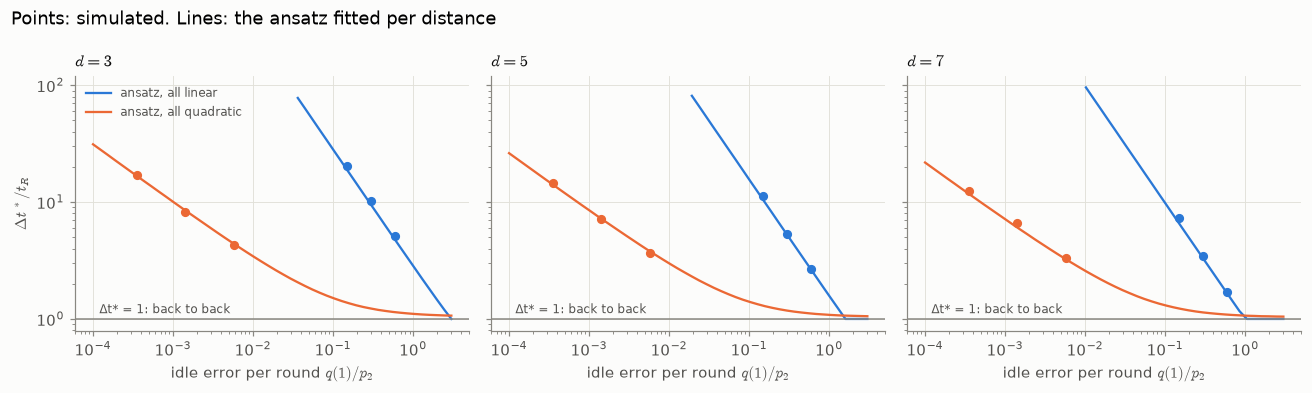

In [5]:
from qec_timing.studies.idle_scaling import q_idle
place, p2, T_ = isc["setup"]["placement"], isc["setup"]["p2"], isc["setup"]["T"]
fig, axes = plt.subplots(1, len(isc["rows"]), figsize=(4 * len(isc["rows"]), 3.6), sharey=True)
for ax, r in zip(np.atleast_1d(axes), isc["rows"]):
    for fam, col in (("lin", P.SERIES[0]), ("quad", P.SERIES[1])):
        F = [q for q in r["formula"][fam] if q["dt_star"] < T_ / 2]      # inside a run of T = 192 t_R
        ax.plot([q["q_over_p2"] for q in F], [q["dt_star"] for q in F], "-", color=col, lw=1.5,
                label=f"ansatz, all {'linear' if fam == 'lin' else 'quadratic'}")
        cs = [c for c in r["curves"] if c["family"] == fam]
        q1 = [float(q_idle(1.0, *((c["value"] * p2, 0.0) if fam == "lin" else (0.0, c["value"] * p2)), place)) / p2
              for c in cs]
        ax.plot(q1, [c["optimum"]["dt_star"] for c in cs], "o", color=col, ms=5)
    ax.axhline(1, color=P.MUTED, lw=1); ax.text(1.2e-4, 1.12, "Δt* = 1: back to back", color=P.INK_2, fontsize=8)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(P.dl(r["d"]), loc="left")
    ax.set_xlabel(r"idle error per round $q(1) / p_2$")
np.atleast_1d(axes)[0].set_ylabel(r"$\Delta t^* / t_R$"); np.atleast_1d(axes)[0].legend(fontsize=8)
fig.suptitle("Points: simulated. Lines: the ansatz fitted per distance", x=0.01, ha="left")
fig.tight_layout()
P.save(fig, "07_dt_star_vs_idle_strength_2")

**Reading.**
- *Measured:* Δt* follows the power laws the ansatz implies: slopes −1.00, −1.04, −1.05 (± 0.02)
  for linear idle against −1, and −0.49, −0.49, −0.48 (± 0.01) for quadratic against −0.5, at
  d = 3, 5, 7. At d = 5 and 7 the linear slopes are 2–2.6σ steeper than predicted; each line
  has three points.
- *Measured:* idle on every qubit lengthens Δt* by 1–16% against idle on the data only (the
  original repo's setup, table above), most for strong quadratic idle at d = 7.
- *Measured:* with q(Δt) composed as the circuit applies it, the ansatz fits with χ²/dof = 16,
  37, 97 at d = 3, 5, 7 (statistical errors only, ~0.5% per point). The misfit grows with d;
  idle on the ancillas, which the ansatz does not represent, is the likely remainder.
- *Measured:* the fitted α corresponds to g = 0.73, 0.58, 0.49, below the paper's 0.8 and
  falling with d, unlike the paper's model (notebook 02), where g rises towards 0.8.
- *Interp.:* the lines run far outside the simulated points (q(1)/p2 ≈ 4×10⁻⁴ to 0.6): read
  them as extrapolation. Δt* cannot fall below 1 (the wait cannot be negative), so it
  approaches back to back rather than crossing it.

## Where waiting pays, over the whole idle plane

The calibrated ansatz's Δt* over the plane of linear and quadratic idle strength, per distance.
Inside the dashed box simulations exist (the six fitted curves sit on its edges); outside it
the formula is extrapolated (pale). The white line is where an optimised interval buys less
than 5% over back to back (gain R(1)/R(Δt*) = 1.05); beyond it, waiting is not worth it.
The star is a simulation with **both** idle terms that was held out of the fit, the test of
the formula. The dark line is H2-1E's emulator idle rates for round durations t_R from 1 to
300 ms: the device's position in this plane is set by t_R (γ/p2 ∝ t_R, c/p2 ∝ t_R²).

*Assumption:* the axes are idle strength relative to p2, so the map built at scaled gates
(p2 = 5×10⁻³) is read at H2's own p2; notebook 07 of the original repo checked that halving
all rates leaves Δt* unchanged.

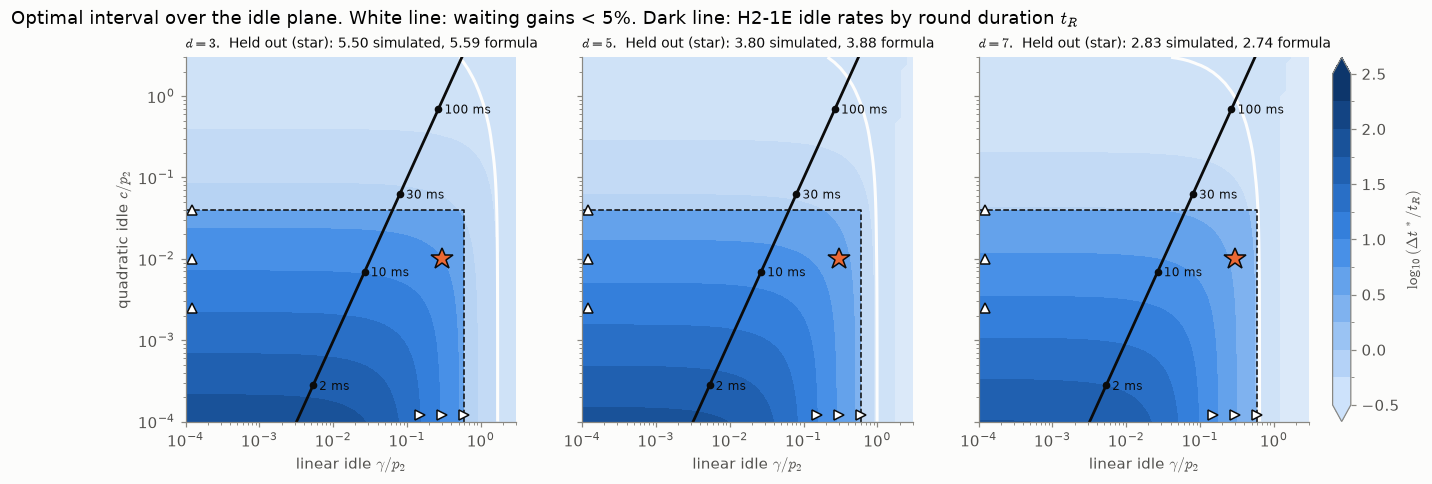

In [6]:
import math
from matplotlib.colors import BoundaryNorm
cal = json.loads((Path("..") / "config" / "h2_1e_emulator.json").read_text())
omega = 2 * math.pi * cal["quad_rate"] * cal["quad_factor"]          # "cycles" reading
tR = np.geomspace(1e-3, 0.3, 60)
h2_g = cal["gamma"] * tR / cal["p2"]; h2_c = (omega * tR / 2) ** 2 / cal["p2"]
fig, axes = plt.subplots(1, len(isc["rows"]), figsize=(4.6 * len(isc["rows"]), 4.3), sharey=True)
levels = np.arange(-0.5, 2.51, 0.25)
cmap = P.sequential_cmap(); norm = BoundaryNorm(levels, cmap.N)
lin, quad = isc["setup"]["lin"], isc["setup"]["quad"]
for ax, r in zip(np.atleast_1d(axes), isc["rows"]):
    ax_ = np.array(r["map"]["axis"]); Z = np.log10(np.array(r["map"]["dt_star"]))
    cs = ax.contourf(ax_, ax_, Z, levels=levels, cmap=cmap, norm=norm, extend="both")
    G = np.array(r["map"]["gain"])
    ax.contour(ax_, ax_, G, levels=[1.05], colors="white", linewidths=2)
    # extrapolated region: everything outside the simulated box
    box = (min(lin), max(lin), min(quad), max(quad))
    from matplotlib.patches import Rectangle
    for x0, y0, x1, y1 in ((box[1], ax_[0], ax_[-1], ax_[-1]), (ax_[0], box[3], box[1], ax_[-1])):
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, color=P.SURFACE, alpha=0.55, lw=0, zorder=2))
    ax.plot([ax_[0], box[1], box[1]], [box[3], box[3], ax_[0]], "--", color=P.INK, lw=1)
    ax.plot(lin, [ax_[1]] * 3, ">", color="white", mec=P.INK, ms=7)
    ax.plot([ax_[1]] * 3, quad, "^", color="white", mec=P.INK, ms=7)
    h = r["held_out"]
    ax.plot(h["gamma_over_p2"], h["c_over_p2"], "*", color=P.SERIES[1], mec=P.INK, ms=15)

    ax.plot(h2_g, h2_c, "-", color=P.INK, lw=1.8)
    for t in (2e-3, 1e-2, 3e-2, 0.1, 0.3):
        g_, c_ = cal["gamma"] * t / cal["p2"], (omega * t / 2) ** 2 / cal["p2"]
        if g_ > ax_[0] and c_ > ax_[0]:
            ax.plot(g_, c_, "o", color=P.INK, ms=4)
            ax.annotate(f"{t*1e3:g} ms", (g_, c_), xytext=(4, -3), textcoords="offset points", fontsize=8, color=P.INK)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(False)
    ax.set_xlim(ax_[0], ax_[-1]); ax.set_ylim(ax_[0], ax_[-1])
    ax.set_xlabel(r"linear idle $\gamma / p_2$")
    ax.set_title(rf"$d = {r['d']}$.  Held out (star): {h['optimum']['dt_star']:.2f} simulated, {h['formula_dt_star']:.2f} formula",
                 loc="left", fontsize=9)
np.atleast_1d(axes)[0].set_ylabel(r"quadratic idle $c / p_2$")
fig.colorbar(cs, ax=axes, label=r"$\log_{10}(\Delta t^* / t_R)$", fraction=0.025, pad=0.02)
fig.suptitle(r"Optimal interval over the idle plane. White line: waiting gains < 5%. Dark line: H2-1E idle rates by round duration $t_R$", x=0.01, ha="left")
P.save(fig, "07_dt_star_vs_idle_strength_3")

**Reading.**
- *Measured:* the held-out simulation (both idle terms at once) is predicted to within 1.6%,
  2.1% and 3.2% (Δt* 5.50, 3.80, 2.83 simulated against 5.59, 3.88, 2.74 at d = 3, 5, 7);
  inside the box the map is a calibrated prediction, not just a fit.
- *Interp.:* along H2-1E's trajectory the formula gives a gain of ×30–45 at t_R = 1 ms and
  ×1.6–2.1 at 30 ms; the gain falls below 5% from t_R ≈ 120 ms (d = 7), 150 ms (d = 5) and
  200 ms (d = 3). These points lie outside the box: a fitted formula at scaled gates,
  extrapolated, not a simulation at H2's own rates.
- *Limits:* outside the box (pale) the formula is extrapolated; the quadratic search stops at
  the term's first maximum, where the twirled model stops describing decoherence.